In [ ]:
import os
import zipfile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models.feature_extraction import create_feature_extractor

from tqdm import tqdm

In [ ]:
!gdown "1_SSG-CeOv9ORh_1fTqmibCZ8Xu28tk0S"

Downloading...
From (original): https://drive.google.com/uc?id=1_SSG-CeOv9ORh_1fTqmibCZ8Xu28tk0S
From (redirected): https://drive.google.com/uc?id=1_SSG-CeOv9ORh_1fTqmibCZ8Xu28tk0S&confirm=t&uuid=2bbe1052-8da3-49af-92de-15695e318649
To: /content/before clean dataset.zip
100% 625M/625M [00:07<00:00, 86.1MB/s]


In [ ]:
!unzip -q "/content/before clean dataset.zip" -d /content/beforeCleanDataset

In [ ]:
!pip install split-folders

In [ ]:
import splitfolders

# input_folder: the path where your 12 class folders are
# output_folder: where the train/val/test folders will be created
splitfolders.ratio("/content/beforeCleanDataset/before clean dataset", output="/content/dataset_split",
                   seed=42, ratio=(.8, .1, .1), move=False)

Copying files: 31548 files [00:12, 2546.05 files/s]


# **Step 1: Setup and Environment**

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Step 2: Define the PCSA Mechanism

In [78]:
class PCSA(nn.Module):
    def __init__(self, in_channels, r=16):
        super().__init__()
        # Channel Branch
        self.fc = nn.Sequential(
            nn.Linear(in_channels, in_channels // r),
            nn.ReLU(inplace=True),
            nn.Linear(in_channels // r, in_channels),
            nn.Sigmoid() # Keeps weights <= 1.0
        )
        # Spatial Branch
        self.spatial_conv = nn.Conv2d(2, 1, kernel_size=7, padding=3)
        self.sigmoid = nn.Sigmoid() # Keeps weights <= 1.0

    def forward(self, x):
        # 1. Get Attention Masks (Sigmoid ensures these are 0.0 to 1.0)
        b, c, _, _ = x.size()

        # Channel Mask
        y_c = x.mean((2, 3))
        channel_mask = self.fc(y_c).view(b, c, 1, 1) # Sigmoid is inside self.fc

        # Spatial Mask
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        y_s = torch.cat([avg_out, max_out], dim=1)
        spatial_mask = self.sigmoid(self.spatial_conv(y_s))

        # 2. THE STABLE FUSION
        # Instead of (x*mask) * (x*mask), we do x * (mask * mask)
        # This applies both attentions to x WITHOUT squaring x.
        combined_mask = channel_mask * spatial_mask
        out = x * combined_mask

        return torch.relu(out)

In [90]:
class PCSABlockWrapper(nn.Module):
    def __init__(self, original_block):
        super().__init__()
        self.block = original_block
        self.pcsa = PCSA(original_block.conv3.out_channels)

    def forward(self, x):
        identity = x
        # Standard ResNet block logic
        out = self.block(x)

        # Apply PCSA as a 'refinement'
        # Adding a residual here ensures that even if PCSA outputs 0,
        # the model doesn't lose the pre-trained features.
        refined = self.pcsa(out)

        return torch.relu(refined + out) # Residual bridge

def get_resnet50_pcsa(num_classes=12):
    model = models.resnet50(pretrained=True)

    # Inject PCSA into every bottleneck block safely
    for layer_name in ['layer1', 'layer2', 'layer3', 'layer4']:
        layer = getattr(model, layer_name)
        for i in range(len(layer)):
            layer[i] = PCSABlockWrapper(layer[i])

    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

In [91]:

model = get_resnet50_pcsa(num_classes=12)


In [ ]:
# import torchvision.models as models

# # 1. Load the standard pre-trained ResNet-50
# model = models.resnet50(pretrained=True)

# # 2. Replace the final layer for your 12 classes
# num_ftrs = model.fc.in_features
# model.fc = nn.Linear(num_ftrs, 12)

# # 3. Move to GPU
# model = model.to(device)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


# **Step 4: Data Augmentation and Loading**

In [92]:
# Simple Gaussian Noise
class AddGaussianNoise(object):
    def __init__(self, mean=0., std=1.):
        self.std = std
        self.mean = mean
    def __call__(self, tensor):
        return tensor + torch.randn(tensor.size()) * self.std + self.mean

# Exact same methods proposed by paper
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)), # Image normalization
    # transforms.RandomHorizontalFlip(), # Basic
    # transforms.RandomRotation([0, 270]), # Spin
    # transforms.ColorJitter(brightness=0.2, contrast=0.2), # Color jitter
    # Note: Zoom and Gaussian noise usually require custom logic or specific
    # torchvision versions. Here we use standard equivalents.
    # transforms.RandomResizedCrop(224, scale=(0.8, 1.0)), # Zoom simulation
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Assuming dataset is organized in class folders
train_dataset = datasets.ImageFolder('/content/dataset_split/train', transform=train_transforms)
val_dataset = datasets.ImageFolder('/content/dataset_split/val', transform=val_transforms)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)

# **Step 5: Training Setup**

In [93]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001) # Start slightly smaller for Adam
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=2)

# **Step 6: Training and Evaluation Loops**

In [94]:
from tqdm.notebook import tqdm
import time

def train_model(model, train_loader, val_loader, epochs=6):
    best_acc = 0.0
    history = {'train_acc': [], 'val_acc': [], 'train_loss': []}

    print('Training begins...')
    for epoch in range(epochs):
        start_time = time.time()

        # --- Training Phase ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        # Create a progress bar for the training loader
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", unit="batch")

        for inputs, labels in train_pbar:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

            # Show the current loss in the progress bar
            train_pbar.set_postfix(loss=f"{loss.item():.4f}")

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = 100 * correct_train / total_train

        # --- Validation Phase ---
        model.eval()
        correct_val = 0
        total_val = 0

        # Optional: Add a second progress bar for validation (disappears after finish)
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]", unit="batch", leave=False)

        with torch.no_grad():
            for inputs, labels in val_pbar:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        val_acc = 100 * correct_val / total_val

        # Update Learning Rate
        scheduler.step(val_acc)

        # Save History
        history['train_acc'].append(epoch_acc)
        history['val_acc'].append(val_acc)
        history['train_loss'].append(epoch_loss)

        epoch_duration = time.time() - start_time
        print(f'Epoch {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.2f}% | Val Acc: {val_acc:.2f}% | Time: {epoch_duration:.0f}s')

        # Save Best Model
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), 'best_pcsa_model.pth')

    return history

In [95]:
# Launch training
history = train_model(model, train_loader, val_loader, epochs=6)

Training begins...


Epoch 1/6 [Train]:   0%|          | 0/789 [00:00<?, ?batch/s]

Epoch 1/6 [Val]:   0%|          | 0/99 [00:00<?, ?batch/s]

Epoch 1/6 | Loss: 0.3341 | Train Acc: 87.57% | Val Acc: 92.01% | Time: 435s


Epoch 2/6 [Train]:   0%|          | 0/789 [00:00<?, ?batch/s]

Epoch 2/6 [Val]:   0%|          | 0/99 [00:00<?, ?batch/s]

... (9 outputs left out)

Epoch 5/6 | Loss: 0.0614 | Train Acc: 97.64% | Val Acc: 94.42% | Time: 435s


Epoch 6/6 [Train]:   0%|          | 0/789 [00:00<?, ?batch/s]

Epoch 6/6 [Val]:   0%|          | 0/99 [00:00<?, ?batch/s]

Epoch 6/6 | Loss: 0.0275 | Train Acc: 98.87% | Val Acc: 95.75% | Time: 437s


# **Step 7: Visualization (Graph Types)**

In [96]:
def plot_training_history(history):
    plt.figure(figsize=(10, 6))
    plt.plot(history['train_acc'], label='Training Accuracy', color='blue')
    plt.plot(history['val_acc'], label='Validation Accuracy', color='red', linestyle='--')
    plt.title('Training and Validation Accuracy Curves') # Matching Figure 8 [cite: 181]
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.grid(True)
    plt.show()

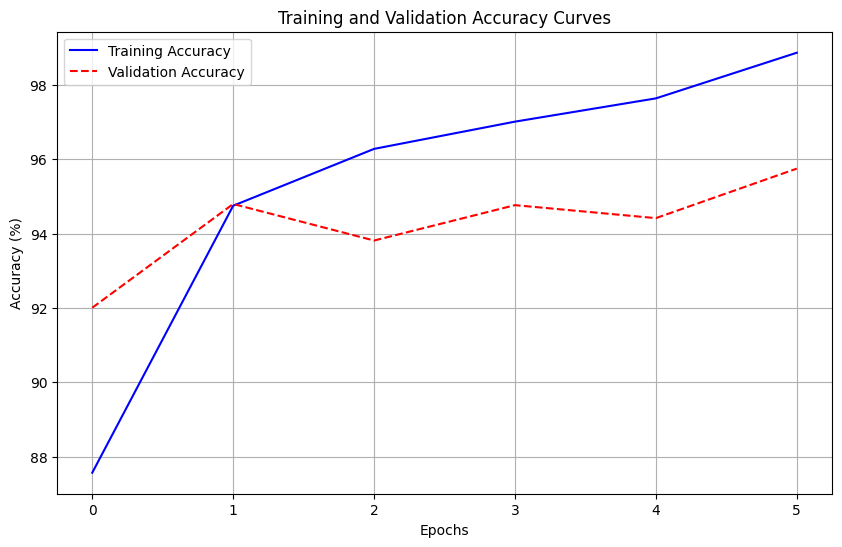

In [97]:
plot_training_history(history)

# **Step 8: Confusion Matrix and Scoring**

In [98]:
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_final_model(model, test_loader, class_names):
    model.load_state_dict(torch.load('best_pcsa_model.pth'))
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    # Detailed Scoring (P, R, F1) [cite: 180]
    print("\nClassification Report (Precision, Recall, F1):")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix for 12 Classes')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

In [99]:
import seaborn as sns

# Create the test loader
test_dataset = datasets.ImageFolder('/content/dataset_split/test', transform=val_transforms)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)

# Get the class names directly from the dataset
class_names = test_dataset.classes


Classification Report (Precision, Recall, F1):
                           precision    recall  f1-score   support

        Acalymma_vittatum       1.00      1.00      1.00       219
          Achatina_fulica       1.00      1.00      1.00       256
                 Alticini       0.89      0.84      0.86       278
              Ampelophaga       1.00      1.00      1.00       279
Leptinotarsa_decemlineata       1.00      1.00      1.00       268
                  Miridae       0.95      0.89      0.92       253
      Potosiabre vitarsis       0.99      1.00      1.00       265
                   Thrips       1.00      1.00      1.00       227
              grasshopper       1.00      1.00      1.00       277
              leaf beetle       0.84      0.90      0.87       276
    legume blister beetle       1.00      0.99      1.00       294
             lytta polita       0.90      0.95      0.93       267

                 accuracy                           0.96      3159
            

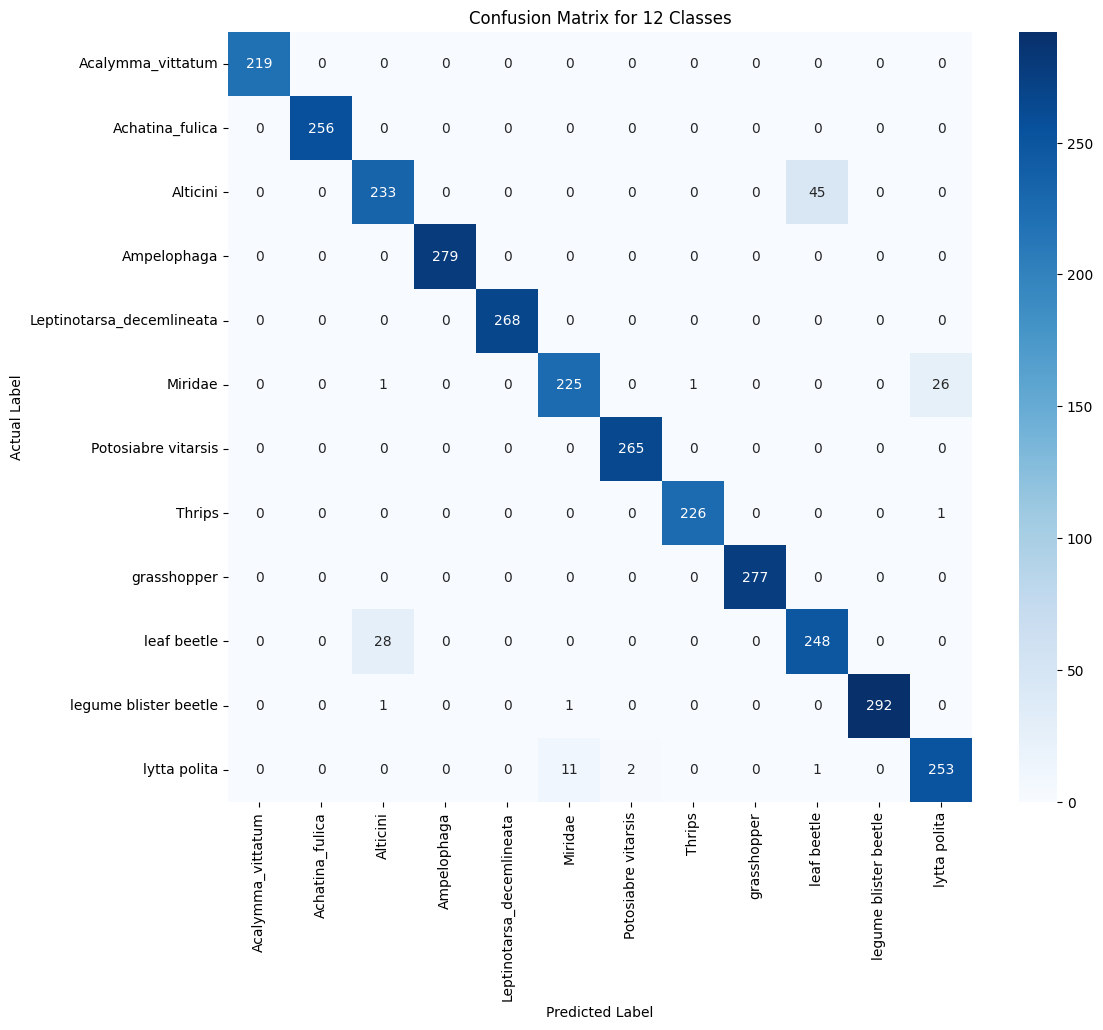

In [100]:
# This will load 'best_pcsa_model.pth', predict the test set, and plot the results
evaluate_final_model(model, test_loader, class_names)